### **SubGraph in LangGraph - Shared State SubGraph**
*A SubGraph in LangGraph usually means a graph that is embedded and executed as a node inside another graph.*

# Invoking a Subgraph from a Node (Isolated State)

## Concept
In this pattern, the parent graph and the subgraph are treated as separate entities. Each one maintains its own independent state.

The subgraph is treated as a black box:
- the parent graph sends only the required inputs
- the subgraph processes them internally
- the parent graph receives only the necessary outputs
- those outputs are manually mapped back into the parent state

---

## How it Works
This pattern creates a clean boundary between the parent workflow and the subgraph workflow.

1. The parent graph keeps its own state.
2. A node in the parent graph calls a subgraph.
3. The subgraph receives only the required data.
4. The subgraph executes independently without directly sharing its internal state.
5. The returned result is manually merged into the parent state.

This means the subgraph is not tightly coupled to the parent graph’s internal state.

---

## Why Use This Pattern?
This is useful when you want:
- strong isolation
- modularity
- easier debugging
- safer execution boundaries

### Key Benefits
- Maximum Isolation
  - Errors or state changes inside the subgraph do not affect the parent graph.
- High Modularity
  - The subgraph can be designed, tested, and maintained independently.
- Better Control
  - You explicitly decide what data is passed in and out.
- Easier Debugging
  - Failures are easier to localize because the subgraph remains separate.

---

## Core Idea
Think of the subgraph as a controlled function:

- Input: only the data it needs
- Output: only the result it produces
- State: kept internal to the subgraph

This makes the system more predictable and easier to reason about.

---

## Example
```python
parent_state = {
    "user_input": "some query",
    "context": "some context",
    "history": ["step 1", "step 2"]
}

subgraph_input = {
    "user_input": parent_state["user_input"],
    "context": parent_state["context"]
}

subgraph_output = subgraph.invoke(subgraph_input)

parent_state["result"] = subgraph_output["final_answer"]

In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

**Define State of Shared Graph & Graph**

In [3]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [4]:
parent_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")
subgraph_llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [6]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [7]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [8]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [9]:

parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

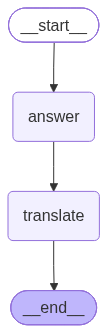

In [10]:
graph = parent_builder.compile()

graph

In [11]:

graph.invoke({'question': 'how the job market will be for Data Scientists role as AI is taking over, in max 5 to 6 lines and what will be the exact tech stack needed to stay in market and crack interviews for 3 to 5 years YOE?'})

{'question': 'how the job market will be for Data Scientists role as AI is taking over, in max 5 to 6 lines and what will be the exact tech stack needed to stay in market and crack interviews for 3 to 5 years YOE?',
 'answer_eng': "The Data Scientist job market is **evolving**, not disappearing, due to AI. AI will automate routine tasks like feature engineering and basic model selection. This shifts the Data Scientist's focus towards higher-level problem formulation, strategic insights, deep domain expertise, ethical AI, and complex model interpretation/deployment. Demand will remain strong for those adapting to these new paradigms, potentially blending with ML Engineering, emphasizing architecting and operationalizing AI solutions rather than just building models.\n\nFor 3-5 years YOE, the essential tech stack to stay competitive and crack interviews includes:\n\n1.  **Programming & Core ML:** Advanced Python (Pandas, NumPy, Scikit-learn).\n2.  **Deep Learning:** Proficiency in Tensor